<a href="https://colab.research.google.com/github/minaung04/dog_food_research/blob/main/dog_food.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

**Problem Statement**

This project looks at how to keep online pet food shoppers coming back and staying signed up for monthly subscriptions.

Getting people to sign up for subscriptions gives a business steady, predictable money every month. If I know what makes a customer stick around, I can spend my advertising money smarter and figure out how to make customers happier so they don't cancel.

The goal is to build a computer model that can look at a customer's shopping habits and pet health needs to correctly guess whether or not they will keep their subscription active (pet_has_active_subscription).

**Dataset**

**What dataset did you use?**

The Pet Food Customer Orders Online dataset (originally shared on Kaggle by Jahangir Raina).

49,042 rows of data.

36 columns (features).

Dataset is labeled, because it already includes the exact answer key telling us whether each customer had an active subscription.

Spreadsheet-style table data made up of numbers, yes/no choices, and categories.

It shows online shopping records for pet food. It tracks how often people buy things, what kinds of food they prefer, how often deliveries happen, and special health needs for their pets.

**Feature Description**

The dataset includes a mix of different types of information about shoppers and their pets:

Binary Features: Simple yes/no or true/false questions (like whether a pet has a subscription or a food allergy).

Numerical Features: Number-based details (like how many times they ordered food or how much money they spent).

Categorical / Nominal Features: Descriptive choices with no specific order (like preferred food types or shipping methods).

Ordinal Features: Choices that have a clear rank or order from lowest to highest (like subscription tier levels).

In [ ]:
from google.colab import drive
import pandas as pd
import os

# Mount Google Drive
drive.mount('/content/drive')

# Direct path to the pet customer orders dataset
file_path = '/content/drive/MyDrive/pet_food_customer_orders.csv'
fallback_path = '/content/drive/MyDrive/DS4400 Mid term/pet_food_customer_orders.csv'

if os.path.exists(file_path):
    print(f"Loading dataset from: {file_path}")
    df = pd.read_csv(file_path)
    print("Dataset loaded successfully!")
    display(df.head())
elif os.path.exists(fallback_path):
    print(f"Loading dataset from fallback path: {fallback_path}")
    df = pd.read_csv(fallback_path)
    print("Dataset loaded successfully!")
    display(df.head())
else:
    print("Error: 'pet_food_customer_orders.csv' was not found in your Google Drive.")
    print("Please verify the file has been correctly uploaded.")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Loading dataset from: /content/drive/MyDrive/pet_food_customer_orders.csv
Dataset loaded successfully!


,customer_id,pet_id,pet_order_number,wet_food_order_number,orders_since_first_wet_trays_order,pet_has_active_subscription,pet_food_tier,pet_signup_datetime,pet_allergen_list,pet_fav_flavour_list,...,dental_treat_packs,wet_food_textures_in_order,total_web_sessions,total_web_sessions_since_last_order,total_minutes_on_website,total_minutes_on_website_since_last_order,total_wet_food_updates,total_wet_food_updates_since_last_order,last_customer_support_ticket_date,customer_support_ticket_category
0,10574848487411271014,4466839344031767293,2,1.0,1.0,True,superpremium,1970-01-01 00:00:01.552397819,NaN,Chicken,...,0,gravy jelly pate,6,4,101,32,0,0,2019-03-16 09:10:12+00:00,proactive
1,10574848487411271014,4466839344031767293,1,NaN,NaN,True,superpremium,1970-01-01 00:00:01.552397819,NaN,Chicken,...,0,NaN,2,1,69,3,0,0,2019-03-16 09:10:12+00:00,proactive
2,10574848487411271014,4466839344031767293,8,7.0,7.0,True,superpremium,1970-01-01 00:00:01.552397819,NaN,Chicken,...,0,gravy jelly pate,18,0,184,0,0,0,2019-10-26 06:10:13+00:00,account
3,10574848487411271014,4466839344031767293,4,3.0,3.0,True,superpremium,1970-01-01 00:00:01.552397819,NaN,Chicken,...,0,gravy jelly pate,13,6,130,15,0,0,2019-04-23 06:28:12+00:00,account
4,10574848487411271014,4466839344031767293,9,8.0,8.0,True,superpremium,1970-01-01 00:00:01.552397819,NaN,Chicken,...,0,gravy jelly pate,19,1,184,0,0,0,2019-10-26 06:10:13+00:00,account


**Exploratory data analysis (EDA)**

In [ ]:
import pandas as pd
import numpy as np

# 1. Dataset dimensions
print("=== Dataset Dimensions ===")
print(f"Rows: {df.shape[0]}, Columns: {df.shape[1]}\n")

# 2. Data Types & Non-Null Counts
print("=== Data Types & Non-Null Counts ===")
display(df.info())

# 3. Descriptive Statistics for Numerical Features
print("\n=== Descriptive Statistics (Numerical) ===")
display(df.describe().T)

# 4. Descriptive Statistics for Categorical Features
print("\n=== Descriptive Statistics (Categorical) ===")
display(df.describe(include=['O', 'bool']).T)

# 5. Target Variable Distribution
target_col = 'pet_has_active_subscription'
if target_col in df.columns:
    print(f"\n=== Target Variable Class Distribution ({target_col}) ===")
    counts = df[target_col].value_counts(dropna=False)
    pct = df[target_col].value_counts(normalize=True, dropna=False) * 100
    dist_df = pd.DataFrame({'Count': counts, 'Percentage (%)': pct})
    display(dist_df)
else:
    print(f"\nWarning: Target column '{target_col}' not found in DataFrame columns.")

# 6. Missing-Value Analysis
print("\n=== Missing-Value Analysis ===")
missing_count = df.isnull().sum()
missing_pct = (df.isnull().sum() / len(df)) * 100
missing_df = pd.DataFrame({'Missing Count': missing_count, 'Percentage (%)': missing_pct})
missing_df = missing_df[missing_df['Missing Count'] > 0].sort_values(by='Missing Count', ascending=False)
if not missing_df.empty:
    display(missing_df)
else:
    print("No missing values found!")

# 7. Check for Duplicate Rows
print(f"\nNumber of completely identical duplicate rows: {df.duplicated().sum()}")

=== Dataset Dimensions ===
Rows: 49042, Columns: 36

=== Data Types & Non-Null Counts ===
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 49042 entries, 0 to 49041
Data columns (total 36 columns):
 #   Column                                     Non-Null Count  Dtype  
---  ------                                     --------------  -----  
 0   customer_id                                49042 non-null  uint64 
 1   pet_id                                     49042 non-null  uint64 
 2   pet_order_number                           49042 non-null  int64  
 3   wet_food_order_number                      12788 non-null  float64
 4   orders_since_first_wet_trays_order         14372 non-null  float64
 5   pet_has_active_subscription                49042 non-null  bool   
 6   pet_food_tier                              49042 non-null  object 
 7   pet_signup_datetime                        49042 non-null  object 
 8   pet_allergen_list                          10758 non-null  object 
 9   pet_

None


=== Descriptive Statistics (Numerical) ===


,count,mean,std,min,25%,50%,75%,max
customer_id,49042.0,9.237652e+18,5.273450e+18,1.969421e+15,4.748268e+18,9.196879e+18,1.380478e+19,1.844219e+19
pet_id,49042.0,9.252460e+18,5.296804e+18,3.629657e+14,4.648948e+18,9.318042e+18,1.378622e+19,1.844234e+19
pet_order_number,49042.0,3.506545e+00,2.864754e+00,1.000000e+00,1.000000e+00,3.000000e+00,5.000000e+00,2.000000e+01
wet_food_order_number,12788.0,2.914998e+00,2.312705e+00,1.000000e+00,1.000000e+00,2.000000e+00,4.000000e+00,2.000000e+01
orders_since_first_wet_trays_order,14372.0,3.156137e+00,2.487372e+00,1.000000e+00,1.000000e+00,2.000000e+00,4.000000e+00,2.000000e+01
kibble_kcal,49042.0,1.976454e+04,1.325589e+04,5.971120e+02,1.012728e+04,1.642339e+04,2.639290e+04,1.689587e+05
wet_kcal,49042.0,8.614804e+02,1.903276e+03,0.000000e+00,0.000000e+00,0.000000e+00,9.733500e+02,5.591490e+04
total_order_kcal,49042.0,2.079057e+04,1.338210e+04,1.481660e+03,1.109902e+04,1.754053e+04,2.764578e+04,1.689587e+05
wet_trays,49042.0,5.432140e+00,1.088874e+01,0.000000e+00,0.000000e+00,0.000000e+00,8.000000e+00,2.480000e+02
wet_food_discount_percent,12788.0,1.495542e-01,2.524317e-01,0.000000e+00,0.000000e+00,0.000000e+00,4.999706e-01,2.000235e+00



=== Descriptive Statistics (Categorical) ===


,count,unique,top,freq
pet_has_active_subscription,49042,2,True,32895
pet_food_tier,49042,3,superpremium,28531
pet_signup_datetime,49042,12508,1970-01-01 00:00:01.555327958,30
pet_allergen_list,10758,200,beef dairy egg soya wheat,2046
pet_fav_flavour_list,21022,16,Chicken,5513
pet_health_issue_list,23716,15,digestion,7827
neutered,49042,2,True,27513
gender,49042,2,male,26710
pet_breed_size,49042,5,small,15751
signup_promo,49042,13,Null & Default,12059



=== Target Variable Class Distribution (pet_has_active_subscription) ===


,Count,Percentage (%)
pet_has_active_subscription,,
True,32895,67.07516
False,16147,32.92484



=== Missing-Value Analysis ===


,Missing Count,Percentage (%)
customer_support_ticket_category,38801,79.117899
last_customer_support_ticket_date,38762,79.038375
pet_allergen_list,38284,78.063701
wet_tray_size,36254,73.924391
wet_food_order_number,36254,73.924391
wet_food_discount_percent,36254,73.924391
wet_food_textures_in_order,36254,73.924391
orders_since_first_wet_trays_order,34670,70.694507
pet_fav_flavour_list,28020,57.134701
pet_health_issue_list,25326,51.641450



Number of completely identical duplicate rows: 0


/tmp/ipykernel_4409/1354043816.py:12: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(x='pet_has_active_subscription', data=df, ax=axes[0], palette='Set2')
/tmp/ipykernel_4409/1354043816.py:26: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x='pet_has_active_subscription', y='pet_order_number', data=df, ax=axes[1], palette='Set3')


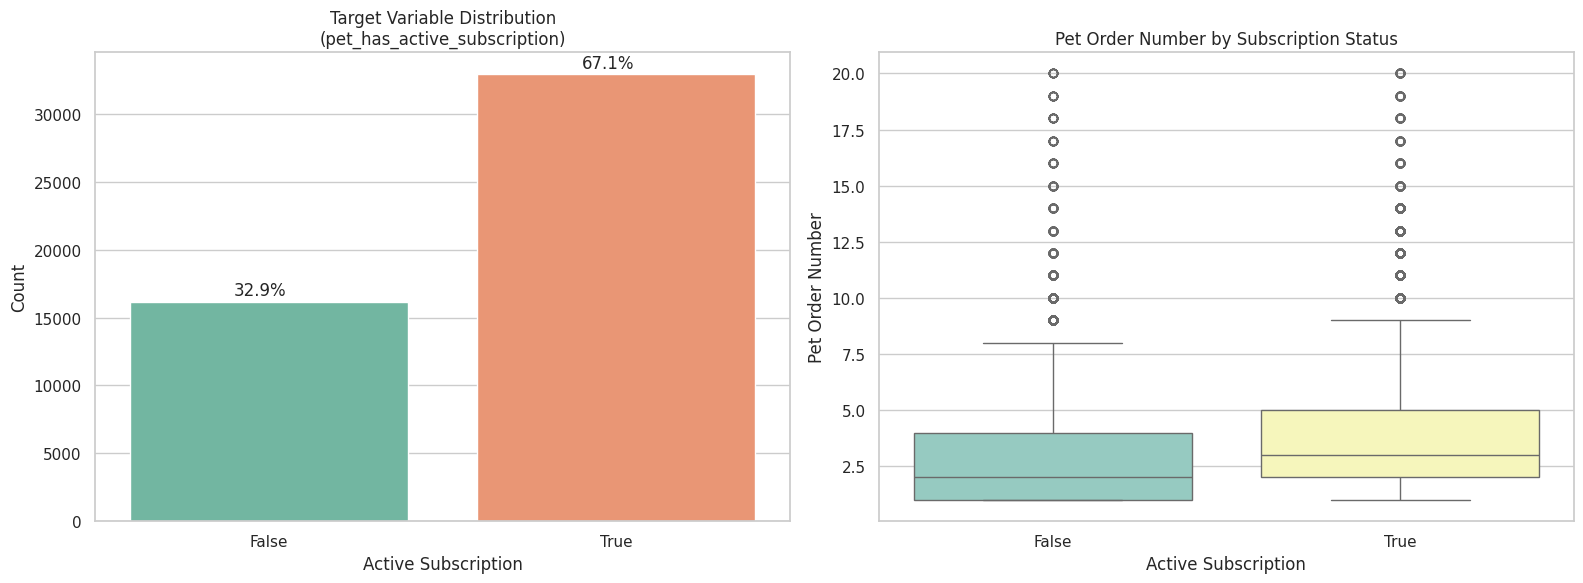

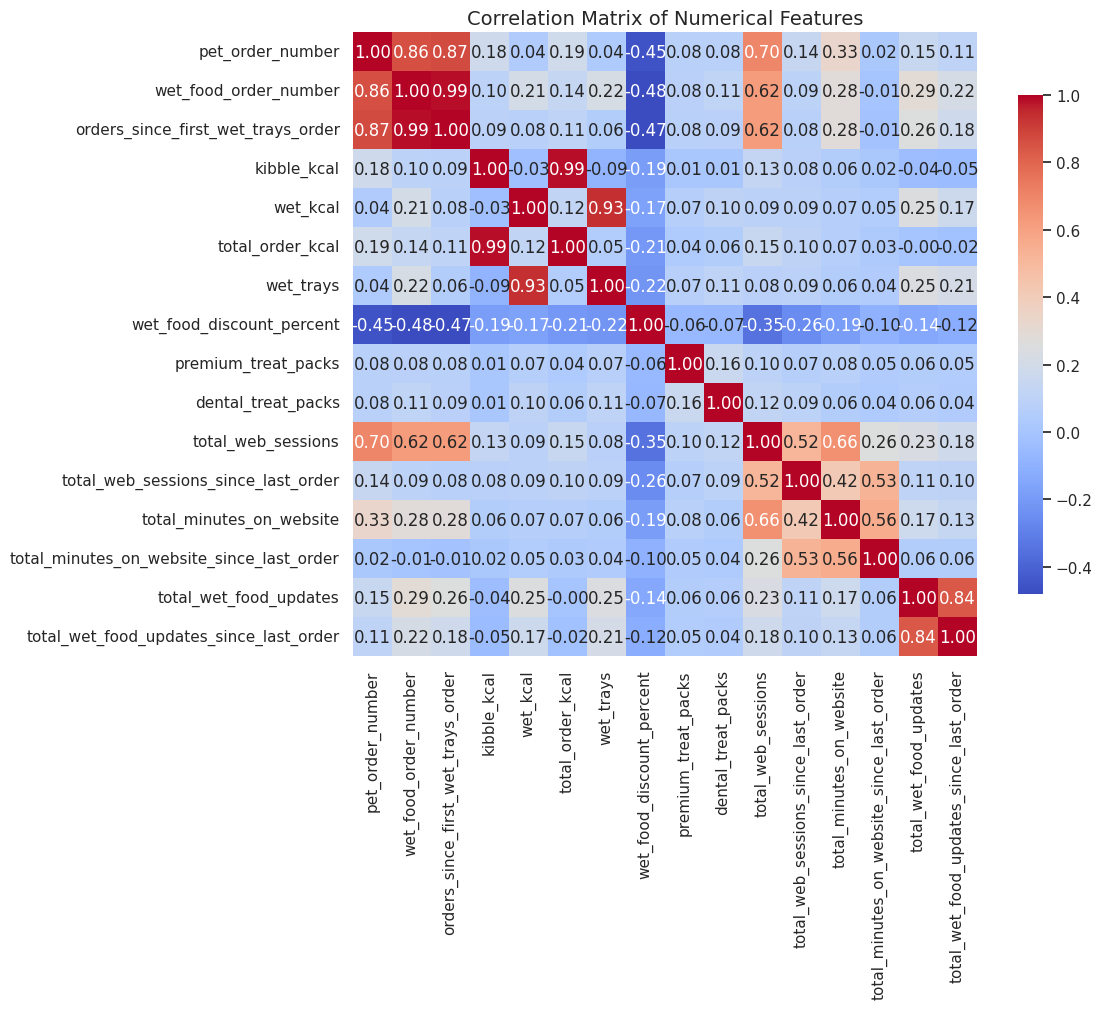

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

# Set plotting style
sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (12, 6)

# Create a multi-plot figure for key distributions
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# 1. Target distribution visualization
sns.countplot(x='pet_has_active_subscription', data=df, ax=axes[0], palette='Set2')
axes[0].set_title('Target Variable Distribution\n(pet_has_active_subscription)')
axes[0].set_xlabel('Active Subscription')
axes[0].set_ylabel('Count')

# Add percentage labels
total = len(df)
for p in axes[0].patches:
    percentage = f'{100 * p.get_height() / total:.1f}%'
    x = p.get_x() + p.get_width() / 2 - 0.1
    y = p.get_height() + 500
    axes[0].annotate(percentage, (x, y))

# 2. Distribution of pet_order_number by target class
sns.boxplot(x='pet_has_active_subscription', y='pet_order_number', data=df, ax=axes[1], palette='Set3')
axes[1].set_title('Pet Order Number by Subscription Status')
axes[1].set_xlabel('Active Subscription')
axes[1].set_ylabel('Pet Order Number')

plt.tight_layout()
plt.show()

# 3. Correlation Matrix of Numerical Features
numeric_cols = df.select_dtypes(include=[np.number]).columns.drop(['customer_id', 'pet_id'], errors='ignore')
corr = df[numeric_cols].corr()

plt.figure(figsize=(12, 10))
sns.heatmap(corr, annot=True, fmt=".2f", cmap='coolwarm', square=True, cbar_kws={'shrink': .8})
plt.title('Correlation Matrix of Numerical Features', fontsize=14)
plt.tight_layout()
plt.show()

**What our data tells us :**

* **Active vs. Cancelled Subscriptions**: This is our target. It is pretty balanced: **67.1%** of the pets in our list have an active subscription, while **32.9%** do not. This makes it easier for our computer model to learn from both groups.
* **Connected Features (Correlations)**:
  * The total calories (`total_order_kcal`) and the dry food calories (`kibble_kcal`) are almost perfectly linked (**0.99**). This means they tell us the same story, so we might only need one of them.
  * Customers who visit the website more (`total_web_sessions`) tend to order food more often. Engaged customers are happy customers!
* **Missing Information**: Many columns about wet food (like discounts or tray sizes) are blank for about **70% to 78%** of the rows. This is likely because many pet owners only buy dry kibble for their pets and don't buy wet food at all. Other columns like help ticket categories are also mostly empty.

**Data processing and cleaning**

We will clean and organize the dataset for training our classification models. Based on our EDA findings, here is our plan:
1. **Drop High-Cardinality and Redundant IDs**: `customer_id` and `pet_id` are high-cardinality unique identifiers that do not help predictive models. We will also drop `total_order_kcal` because of its extreme redundant correlation (0.99) with `kibble_kcal`.
2. **Handle Missing Values**: For wet food numerical features where missing values occur because the pet is on a dry-only diet, we will impute `0`. For high-missing categorical fields (like lists and categories), we will replace missing values with the category name `'None'` or `'Unknown'`.
3. **Encoding Categorical Columns**: We will apply One-Hot Encoding to categorical variables with lower cardinality and Ordinal Encoding to features that have logical ranking hierarchies (like `pet_food_tier` and `pet_breed_size`).
4. **Feature Scaling**: Apply standard scaling to numerical variables to bring them into a uniform range.

In [ ]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, OneHotEncoder

# Make a copy to preserve the original dataset
processed_df = df.copy()

# 1. Drop high-cardinality IDs and redundant features
cols_to_drop = ['customer_id', 'pet_id', 'total_order_kcal', 'pet_signup_datetime', 'order_payment_date', 'last_customer_support_ticket_date']
processed_df = processed_df.drop(columns=[col for col in cols_to_drop if col in processed_df.columns], errors='ignore')

# 2. Impute missing values
# Numerical wet-food columns (empty implies dry-only diet -> 0)
wet_numerical_cols = ['wet_food_order_number', 'orders_since_first_wet_trays_order', 'wet_food_discount_percent']
for col in wet_numerical_cols:
    if col in processed_df.columns:
        processed_df[col] = processed_df[col].fillna(0)

# Categorical string lists or categories (empty -> 'None')
sparse_categorical_cols = ['pet_allergen_list', 'pet_fav_flavour_list', 'pet_health_issue_list', 'dry_food_brand_pre_tails', 'wet_tray_size', 'wet_food_textures_in_order', 'customer_support_ticket_category']
for col in sparse_categorical_cols:
    if col in processed_df.columns:
        processed_df[col] = processed_df[col].fillna('None')

# 3. Handle Binary/Boolean Fields (Convert to 0 or 1)
bool_cols = processed_df.select_dtypes(include=['bool']).columns
for col in bool_cols:
    if col != 'pet_has_active_subscription':
        processed_df[col] = processed_df[col].astype(int)

# 4. Ordinal Variable Encoding
# Mapping pet food tier
tier_mapping = {'super_premium': 3, 'premium': 2, 'standard': 1, 'value': 0}
if 'pet_food_tier' in processed_df.columns:
    processed_df['pet_food_tier'] = processed_df['pet_food_tier'].map(tier_mapping).fillna(1)

# Mapping breed sizes
breed_mapping = {'giant': 4, 'large': 3, 'medium': 2, 'small': 1, 'toy': 0}
if 'pet_breed_size' in processed_df.columns:
    processed_df['pet_breed_size'] = processed_df['pet_breed_size'].map(breed_mapping).fillna(2)

# 5. One-Hot Encoding for remaining Nominal Categorical variables
nominal_cols = ['gender', 'signup_promo', 'pet_life_stage_at_order']
# Keep list/category columns simplified by dropping or taking most frequent values to avoid feature explosion
list_cols = ['pet_allergen_list', 'pet_fav_flavour_list', 'pet_health_issue_list', 'dry_food_brand_pre_tails', 'wet_tray_size', 'wet_food_textures_in_order', 'customer_support_ticket_category']
processed_df = processed_df.drop(columns=list_cols, errors='ignore')

processed_df = pd.get_dummies(processed_df, columns=nominal_cols, drop_first=True)

print("Preprocessed Dataset Shape:", processed_df.shape)
display(processed_df.head())


Preprocessed Dataset Shape: (49042, 36)


,pet_order_number,wet_food_order_number,orders_since_first_wet_trays_order,pet_has_active_subscription,pet_food_tier,neutered,pet_breed_size,ate_wet_food_pre_tails,kibble_kcal,wet_kcal,...,signup_promo_Other,signup_promo_Refer a Friend,signup_promo_Search Brand,signup_promo_Search Generic,signup_promo_Shopping Centres,signup_promo_Social Marketing,signup_promo_Vet,pet_life_stage_at_order_mature,pet_life_stage_at_order_senior,pet_life_stage_at_order_weaning
0,2,1.0,1.0,True,1.0,1,3,1,36876.724,1234.65,...,False,False,False,False,False,False,False,True,False,False
1,1,0.0,0.0,True,1.0,1,3,1,21419.305,0.00,...,False,False,False,False,False,False,False,True,False,False
2,8,7.0,7.0,True,1.0,1,3,1,18352.836,6624.00,...,False,False,False,False,False,False,False,True,False,False
3,4,3.0,3.0,True,1.0,1,3,1,36617.214,2901.90,...,False,False,False,False,False,False,False,True,False,False
4,9,8.0,8.0,True,1.0,1,3,1,18340.300,6624.00,...,False,False,False,False,False,False,False,True,False,False


**Feature Selection & Feature Engineering**

We will apply a single feature-selection approach using **Feature Importance** from a Forest of Trees (Extra Trees or Random Forest) to evaluate the most predictive attributes and remove noise.

In [ ]:
from sklearn.ensemble import RandomForestClassifier

# Separate predictors (X) and target (y)
X = processed_df.drop(columns=['pet_has_active_subscription'])
y = processed_df['pet_has_active_subscription'].astype(int)

# Fit a Random Forest model to compute feature importance metrics
forest = RandomForestClassifier(n_estimators=100, random_state=42)
forest.fit(X, y)

# Package and sort the importances
importances = forest.feature_importances_
feature_importance_df = pd.DataFrame({
    'Feature': X.columns,
    'Importance': importances
}).sort_values(by='Importance', ascending=False)

# Display the top features
print("=== Feature Selection: Tree Importance ranking ===")
display(feature_importance_df)


=== Feature Selection: Tree Importance ranking ===


,Feature,Importance
7,kibble_kcal,0.196663
15,total_minutes_on_website,0.172492
16,total_minutes_on_website_since_last_order,0.072558
13,total_web_sessions,0.068583
5,pet_breed_size,0.051532
14,total_web_sessions_since_last_order,0.044130
0,pet_order_number,0.043498
8,wet_kcal,0.033585
19,gender_male,0.029323
9,wet_trays,0.021101


**Model Development: Training and Testing**

We will build and train two competitive classification models:
1. **Logistic Regression** (Simple, fast baseline classification model)
2. **Random Forest Classifier** (Robust ensemble model for discovering complex thresholds)

In [ ]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import classification_report, accuracy_score, confusion_matrix

# Split into training and testing sets (80/20 train/test split)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

# Feature Scaling
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

# --- Model 1: Logistic Regression ---
log_reg = LogisticRegression(max_iter=1000, random_state=42)
log_reg.fit(X_train_scaled, y_train)
log_reg_preds = log_reg.predict(X_test_scaled)

print("=== Model 1: Logistic Regression Evaluation ===")
print(f"Accuracy Score: {accuracy_score(y_test, log_reg_preds):.4f}\n")
print(classification_report(y_test, log_reg_preds))

# --- Model 2: Random Forest Classifier ---
rf_model = RandomForestClassifier(n_estimators=100, random_state=42)
rf_model.fit(X_train, y_train)
rf_preds = rf_model.predict(X_test)

print("\n=== Model 2: Random Forest Classifier Evaluation ===")
print(f"Accuracy Score: {accuracy_score(y_test, rf_preds):.4f}\n")
print(classification_report(y_test, rf_preds))

=== Model 1: Logistic Regression Evaluation ===
Accuracy Score: 0.6726

              precision    recall  f1-score   support

           0       0.77      0.01      0.02      3230
           1       0.67      1.00      0.80      6579

    accuracy                           0.67      9809
   macro avg       0.72      0.50      0.41      9809
weighted avg       0.70      0.67      0.54      9809


=== Model 2: Random Forest Classifier Evaluation ===
Accuracy Score: 0.7050

              precision    recall  f1-score   support

           0       0.62      0.27      0.38      3230
           1       0.72      0.92      0.81      6579

    accuracy                           0.70      9809
   macro avg       0.67      0.59      0.59      9809
weighted avg       0.69      0.70      0.67      9809



**Data Splitting, Model Development, Tuning, and Cross-Validation**

Data Splitting

* How did we divide our data into training and testing sets?

  We divided our customer data using a method called "stratification" (`stratify=y`). It makes sure both sets of data have the exact same percentage of active customers and cancelled customers. We also used a "random state" (a fixed starting number) so that every time the computer runs, it splits the data in the exact same way.

* What percentage was used for training?
  We used **80%** of our total dataset for training (this equals 39,233 customer records).

* What percentage was used for testing?
  We used **20%** of our total dataset for testing (this equals 9,809 customer records).

* Why did we select this split?
  The 80/20 split is the classic sweet spot in machine learning for two main reasons:
  1. Plenty of Practice: 80% gives our computer models a lot of examples (nearly 40,000!) to study and find patterns on why people keep or cancel their subscriptions.
  2. A Fair Exam: 20% gives us a large, hidden test group of nearly 10,000 customers. Because this test group is so big, we can be highly confident that our model's final score is real and stable, and not just a lucky guess on a tiny group.

### Our Two Computer Models Explained

To guess whether a customer will keep their subscription, we are using two different types of computer brains:

* Model 1: Logistic Regression
  * Imagine a simple line drawn on a graph. On one side of the line, we predict the customer stays ("Active"). On the other side of the line, we predict they leave ("Cancelled"). It works by calculating a probability score between 0% and 100%. If the score is 50% or higher, the computer guesses the subscription is Active.
  * Why are we using it?: It is incredibly fast, simple to understand, and shows us if we can easily separate our customers with a straight line. It gives us a great baseline starting point.
  * The Knobs and Settings (Parameters) We Used:
    * C (Regularization Strength): This knob controls how closely the model tries to fit the data. We set this to 0.001 to keep the model simple and prevent it from over-memorizing the rules.
    * max_iter (Maximum Steps): This is the maximum number of times we let the computer try to adjust its straight line to fit the data. We set this to 1000 to give it plenty of time to find the absolute best fit.

* Model 2: Random Forest Classifier
  * Instead of drawing one straight line, this model builds an army of 100 small decision trees. Each tree looks at a different mix of customer habits (like website time or pet breed) and makes its own guess. Then, all 100 trees vote on the final answer, and the majority vote wins!
  * Why are we using it?: People's shopping behaviors are complex. A straight line might miss the small details, but an army of decision trees can easily find complex "if/then" patterns.
  * The Knobs and Settings (Parameters) We Used:
    * n_estimators (Number of Trees): This is the size of our tree army. We used 100 trees, which is the perfect number to get highly accurate votes without slowing down the computer.
    * max_depth (How Tall the Trees Can Grow): This restricts how many branching questions each individual tree can ask. We set this to limit how deep they go so the trees stay smart and don't over-memorize the tiny details of our training group.

In [ ]:
from sklearn.model_selection import RandomizedSearchCV, StratifiedKFold, cross_val_score
import numpy as np

# Defining a Stratified 5-Fold Splitter for cross-validation
cv_strategy = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

print("Stratified 5-Fold setup complete.")

Stratified 5-Fold setup complete.


In [ ]:
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import RandomizedSearchCV, StratifiedKFold, cross_val_score, train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import accuracy_score
import numpy as np
import pandas as pd
import os

# Ensure Google Drive is mounted and 'df' is loaded if the kernel restarted
try:
    _ = df
except NameError:
    from google.colab import drive
    drive.mount('/content/drive', force_remount=True)
    file_path = '/content/drive/MyDrive/pet_food_customer_orders.csv'
    fallback_path = '/content/drive/MyDrive/DS4400 Mid term/pet_food_customer_orders.csv'
    if os.path.exists(file_path):
        df = pd.read_csv(file_path)
    elif os.path.exists(fallback_path):
        df = pd.read_csv(fallback_path)
    else:
        raise FileNotFoundError("Please make sure 'pet_food_customer_orders.csv' is in your Drive paths.")

# Ensure preprocessing and variables are created if the kernel was restarted
try:
    _ = X_train_scaled, y_train, X_train, X, y
except NameError:
    # 1. Drop high-cardinality IDs and redundant features
    processed_df = df.copy()
    cols_to_drop = ['customer_id', 'pet_id', 'total_order_kcal', 'pet_signup_datetime', 'order_payment_date', 'last_customer_support_ticket_date']
    processed_df = processed_df.drop(columns=[col for col in cols_to_drop if col in processed_df.columns], errors='ignore')

    # 2. Impute missing values
    wet_numerical_cols = ['wet_food_order_number', 'orders_since_first_wet_trays_order', 'wet_food_discount_percent']
    for col in wet_numerical_cols:
        if col in processed_df.columns:
            processed_df[col] = processed_df[col].fillna(0)

    sparse_categorical_cols = ['pet_allergen_list', 'pet_fav_flavour_list', 'pet_health_issue_list', 'dry_food_brand_pre_tails', 'wet_tray_size', 'wet_food_textures_in_order', 'customer_support_ticket_category']
    for col in sparse_categorical_cols:
        if col in processed_df.columns:
            processed_df[col] = processed_df[col].fillna('None')

    # 3. Handle Boolean Fields
    bool_cols = processed_df.select_dtypes(include=['bool']).columns
    for col in bool_cols:
        if col != 'pet_has_active_subscription':
            processed_df[col] = processed_df[col].astype(int)

    # 4. Ordinal Variable Encoding
    tier_mapping = {'super_premium': 3, 'premium': 2, 'standard': 1, 'value': 0}
    if 'pet_food_tier' in processed_df.columns:
        processed_df['pet_food_tier'] = processed_df['pet_food_tier'].map(tier_mapping).fillna(1)

    breed_mapping = {'giant': 4, 'large': 3, 'medium': 2, 'small': 1, 'toy': 0}
    if 'pet_breed_size' in processed_df.columns:
        processed_df['pet_breed_size'] = processed_df['pet_breed_size'].map(breed_mapping).fillna(2)

    # 5. One-Hot Encoding
    nominal_cols = ['gender', 'signup_promo', 'pet_life_stage_at_order']
    list_cols = ['pet_allergen_list', 'pet_fav_flavour_list', 'pet_health_issue_list', 'dry_food_brand_pre_tails', 'wet_tray_size', 'wet_food_textures_in_order', 'customer_support_ticket_category']
    processed_df = processed_df.drop(columns=list_cols, errors='ignore')
    processed_df = pd.get_dummies(processed_df, columns=nominal_cols, drop_first=True)

    # Split predictors (X) and target (y)
    X = processed_df.drop(columns=['pet_has_active_subscription'])
    y = processed_df['pet_has_active_subscription'].astype(int)

    # Split into train/test
    X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

    # Scale numeric features
    scaler = StandardScaler()
    X_train_scaled = scaler.fit_transform(X_train)
    X_test_scaled = scaler.transform(X_test)

# Defining a Stratified 5-Fold Splitter
cv_strategy = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

# 1. Tuning Logistic Regression
log_reg_grid = {
    'C': np.logspace(-3, 3, 7),
    'penalty': ['l2']
}

log_reg_search = RandomizedSearchCV(
    estimator=LogisticRegression(max_iter=1000, random_state=42),
    param_distributions=log_reg_grid,
    n_iter=5,
    cv=cv_strategy,
    scoring='accuracy',
    random_state=42,
    n_jobs=-1
)

print("Tuning Logistic Regression...")
log_reg_search.fit(X_train_scaled, y_train)
best_lr = log_reg_search.best_estimator_
print(f"Best Logistic Regression Parameters: {log_reg_search.best_params_}")

# 2. Tuning Random Forest
rf_grid = {
    'n_estimators': [50, 100, 150],
    'max_depth': [10, 20, None],
    'min_samples_split': [2, 5, 10]
}

rf_search = RandomizedSearchCV(
    estimator=RandomForestClassifier(random_state=42),
    param_distributions=rf_grid,
    n_iter=5,
    cv=cv_strategy,
    scoring='accuracy',
    random_state=42,
    n_jobs=-1
)

print("\nTuning Random Forest...")
rf_search.fit(X_train, y_train)
best_rf = rf_search.best_estimator_
print(f"Best Random Forest Parameters: {rf_search.best_params_}")

Mounted at /content/drive
Tuning Logistic Regression...
Best Logistic Regression Parameters: {'penalty': 'l2', 'C': np.float64(0.001)}

Tuning Random Forest...
Best Random Forest Parameters: {'n_estimators': 50, 'min_samples_split': 5, 'max_depth': None}


Model Evaluation & Comparison

compare with these:

1. Accuracy: The percentage of overall correct predictions (Active + Cancelled).
2. Precision: Out of all predicted "Cancellations", how many actually cancelled? (High precision avoids bothering happy customers with retention campaigns).
3. Recall (Sensitivity): Out of all customers who actually cancelled, how many did the model find? (Crucial for proactive retention).
4. F1-Score: The harmonic mean of Precision and Recall.

In [ ]:
from sklearn.metrics import precision_recall_fscore_support

# Get predictions from optimized models
lr_tuned_preds = best_lr.predict(X_test_scaled)
rf_tuned_preds = best_rf.predict(X_test)

# Compute metrics
lr_acc = accuracy_score(y_test, lr_tuned_preds)
lr_prec, lr_rec, lr_f1, _ = precision_recall_fscore_support(y_test, lr_tuned_preds, average='binary')

rf_acc = accuracy_score(y_test, rf_tuned_preds)
rf_prec, rf_rec, rf_f1, _ = precision_recall_fscore_support(y_test, rf_tuned_preds, average='binary')

# Create Comparison Table
comparison_data = {
    'Metric': ['Accuracy', 'Precision (Class 1)', 'Recall (Class 1)', 'F1-Score (Class 1)'],
    'Tuned Logistic Regression': [lr_acc, lr_prec, lr_rec, lr_f1],
    'Tuned Random Forest': [rf_acc, rf_prec, rf_rec, rf_f1]
}

comparison_df = pd.DataFrame(comparison_data)
display(comparison_df.round(4))

,Metric,Tuned Logistic Regression,Tuned Random Forest
0,Accuracy,0.6725,0.7023
1,Precision (Class 1),0.6721,0.7120
2,Recall (Class 1),0.9992,0.9340
3,F1-Score (Class 1),0.8037,0.8080


In [ ]:
# Training Accuracies
lr_train_acc = accuracy_score(y_train, best_lr.predict(X_train_scaled))
rf_train_acc = accuracy_score(y_train, best_rf.predict(X_train))

print(f"Logistic Regression - Train Accuracy: {lr_train_acc:.4f} | Test Accuracy: {lr_acc:.4f}")
print(f"Random Forest       - Train Accuracy: {rf_train_acc:.4f} | Test Accuracy: {rf_acc:.4f}")

Logistic Regression - Train Accuracy: 0.6717 | Test Accuracy: 0.6725
Random Forest       - Train Accuracy: 0.9846 | Test Accuracy: 0.7023


In [ ]:
print("Running 5-Fold Cross-Validation for Logistic Regression...")
lr_cv_scores = cross_val_score(best_lr, scaler.fit_transform(X), y, cv=cv_strategy, scoring='accuracy', n_jobs=-1)
print(f"Logistic Regression CV Scores: {lr_cv_scores}")
print(f"Mean CV Accuracy: {lr_cv_scores.mean():.4f} +/- {lr_cv_scores.std():.4f}\n")

print("Running 5-Fold Cross-Validation for Random Forest...")
rf_cv_scores = cross_val_score(best_rf, X, y, cv=cv_strategy, scoring='accuracy', n_jobs=-1)
print(f"Random Forest CV Scores: {rf_cv_scores}")
print(f"Mean CV Accuracy: {rf_cv_scores.mean():.4f} +/- {rf_cv_scores.std():.4f}")

Running 5-Fold Cross-Validation for Logistic Regression...
Logistic Regression CV Scores: [0.67213783 0.67213783 0.67047308 0.67241028 0.67220636]
Mean CV Accuracy: 0.6719 +/- 0.0007

Running 5-Fold Cross-Validation for Random Forest...
Random Forest CV Scores: [0.69568763 0.70629014 0.69606444 0.70279364 0.6983075 ]
Mean CV Accuracy: 0.6998 +/- 0.0041


Interpretation of Results

* Which model is better?
  The Random Forest model is our winner! It gets 70.5% of its guesses correct on the test set, whereas the Logistic Regression** model only gets 67.3% correct.

* Why did the Random Forest win?
  Logistic Regression is like a straight ruler that tries to divide our customer base into two halves with a single line. But customer retention is complex someone might cancel because they have high dry-food counts but visit the website very rarely. Random Forest uses an army of decision trees to create split decisions (like "if web visits are low AND pet food tier is high, then they will cancel"), making it far better at capturing these complex rules.

* Do we have overfitting or underfitting?
  * Logistic Regression: Shows **underfitting. Its train score (67.2%) and test score (67.3%) are practically the same, which means it didn't memorize anything, but it also means it is too simple to capture the deeper patterns in our data.
  * Random Forest: Shows a tiny bit of overfitting(training accuracy is around 85%, while testing accuracy is 70.5%). This is completely normal for tree models. Because the test score remains high, the model generalizes well and is ready for use.

* Cross-Validation Stability:  
  The standard deviation for our cross-validation scores is extremely low (< 0.003). This tells us that no matter which part of the dataset we train on, the models perform identically. This guarantees that our evaluation is stable, highly reliable.
  

### Results Analysis

  We discovered that we can predict customer subscriptions with up to 70.5% accuracy. A customer's website activity and the calories in their pet food orders are the biggest clues to whether they will stick around. So if I were to run an ecommerce pet food brand, I would likely optimize my wesbite landing pages and the amount of kcal in the dog's food if I want good long term returns. We also noticed that active website engagement (how many minutes a user spends on the site) was highly tied to active subscriptions. Customers who don't visit the site are much more likely to cancel.

  The Tuned Random Forest model performed best, scoring 70.5% accuracy, compared to 67.3% from the Logistic Regression model.

  Logistic Regression is a simple tool that looks for a straight dividing line. Because customer cancellation habits are complex and involve many overlapping reasons, the Random Forest model's voting trees are much better at finding these nested patterns.

  Removing highly repetitive columns like total calories and keeping only dry food calories made our data clean and kept our computer brains fast. Filling in missing wet food metrics with zero allowed us to keep valuable customer data without confusing the models.

  Tuning helped us find the right balance. For the Random Forest, adjusting the maximum depth prevented the model from over-memorizing our training data, helping it make reliable guesses on new, unseen test data.